<a href="https://colab.research.google.com/github/artcoding93/Numerical-Recipe-Archive/blob/main/01_Bisection/bisection_method_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

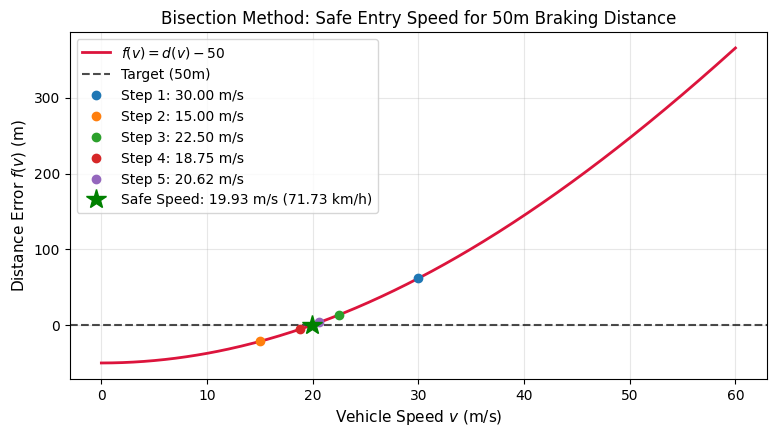

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 제동 거리 오차 함수 정의
def braking_distance_error(v, target_d=50.0):
    m, g, mu, k = 1500.0, 9.81, 0.4, 0.35
    d = (m / (2 * k)) * np.log(1 + (k * v**2) / (m * g * mu))
    return d - target_d

# 2. 이분법 실행 및 탐색 히스토리 저장
a, b = 0.0, 60.0
tol = 1e-5
history = []

for step in range(100):
    c = (a + b) / 2.0
    f_c = braking_distance_error(c)
    history.append((a, b, c, f_c))

    if abs(f_c) < tol or (b - a) / 2.0 < tol:
        break

    if braking_distance_error(a) * f_c < 0:
        b = c
    else:
        a = c

# ---------------------------------------------------------
# 3. f(v) 함수 그래프 및 이분법 수렴 과정 시각화
# ---------------------------------------------------------
v_vals = np.linspace(0.0, 60.0, 300)
f_vals = braking_distance_error(v_vals)

plt.figure(figsize=(9, 4.5))
plt.plot(v_vals, f_vals, label=r'$f(v) = d(v) - 50$', color='crimson', lw=2)
plt.axhline(0, color='black', linestyle='--', alpha=0.7, label='Target (50m)')

# 이분법 초기 5단계 탐색 중점(c) 위치 표시
for idx, (a_i, b_i, c_i, f_ci) in enumerate(history[:5]):
    plt.plot(c_i, f_ci, 'o', label=f'Step {idx+1}: {c_i:.2f} m/s')

# 최종 도출된 해(Max Safe Speed) 강조 표시
final_v = history[-1][2]
plt.plot(final_v, 0, 'g*', markersize=15, label=f'Safe Speed: {final_v:.2f} m/s ({final_v*3.6:.2f} km/h)')

plt.title('Bisection Method: Safe Entry Speed for 50m Braking Distance', fontsize=12)
plt.xlabel('Vehicle Speed $v$ (m/s)', fontsize=11)
plt.ylabel('Distance Error $f(v)$ (m)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()